# 🥈 Artefato de Apoio à Decisão: Previsão de Demanda de Refeições
## Módulo 02: Camada Silver – Padronização, Integração Diária e Auditoria de Qualidade

* **Projeto:** Sistema Preditivo de Refeições – IFSP Campus Itaquaquecetuba
* **Nível:** Mestrado Profissional
* **Arquitetura de Dados:** Medallion Architecture (Bronze ➔ Silver ➔ Gold)

---
### 🎯 Objetivos deste Módulo
1. **Padronização e Tipagem:** Unificar formatos de data (`DD/MM/YYYY` e `ISO`), encodings e nomenclaturas de colunas entre todas as fontes da camada Bronze.
2. **Integração no Grão Diário:** Construir a visão mestra diária unindo **Calendário Acadêmico**, **Cardápio**, **Dados Meteorológicos**, **Histórico de Consumo** e **Registros de Reservas/Estimativas**.
3. **Auditoria de Qualidade e Detecção de Anomalias:**
   - Identificar dias de **dispensa institucional/apagão/queda de luz** (onde a reserva era alta, mas o consumo foi residual, < 40 refeições).
   - Mapear **eventos severos exógenos** (enchentes históricas em Itaquaquecetuba e greves).
   - Caracterizar a **mudança de regime (Concept Drift)** entre a autodeclaração de alunos (2023–2025) e a estimativa técnica da nutricionista (2026).
4. **Governança de Dados:** Criar flags auditáveis na tabela consolidada `silver_fato_diaria` para que os modelos de Machine Learning (Camada Gold) sejam treinados sem vieses espúrios.

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.sans-serif'] = 'Arial'

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


### 1. Carregamento dos Datasets da Camada Silver
Carregamos a tabela fato diária integrada `silver_fato_diaria.parquet` processada a partir dos dados brutos de `dados/bronze/`.

In [2]:
path_silver_fato = "../dados/silver/silver_fato_diaria.parquet"
df_silver = pd.read_parquet(path_silver_fato)

print(f"Total de dias no horizonte temporal (2023 a 2026): {len(df_silver)}")
print(f"Colunas disponíveis: {list(df_silver.columns[:15])} ... (+{len(df_silver.columns)-15} colunas)")
df_silver.head(5)

Total de dias no horizonte temporal (2023 a 2026): 1461
Colunas disponíveis: ['data', 'data_iso', 'dia_da_semana', 'ano', 'mes', 'semestre', 'is_dia_letivo', 'is_fim_de_semana', 'is_sabado_letivo', 'status_legal', 'evento_tipo', 'consumo', 'reservas', 'regime_reserva', 'diff_consumo_reserva'] ... (+31 colunas)


,data,data_iso,dia_da_semana,ano,mes,semestre,is_dia_letivo,is_fim_de_semana,is_sabado_letivo,status_legal,...,apparent_temperature_max,apparent_temperature_min,flag_chuva_persistente,flag_dia_frio,flag_dia_muito_quente,flag_vento_forte,status_dado,arquivo_origem,flag_subnotificacao_reserva,flag_superestimativa_alta
0,01/01/2023,2023-01-01,domingo,2023,1,1,False,True,False,nao_letivo,...,31.9,17.8,True,False,False,False,NaN,NaN,False,False
1,02/01/2023,2023-01-02,segunda-feira,2023,1,1,False,False,False,nao_letivo,...,32.4,17.4,False,False,False,False,NaN,NaN,False,False
2,03/01/2023,2023-01-03,terça-feira,2023,1,1,False,False,False,nao_letivo,...,29.1,20.2,True,False,False,True,NaN,NaN,False,False
3,04/01/2023,2023-01-04,quarta-feira,2023,1,1,False,False,False,nao_letivo,...,28.9,17.6,True,False,False,True,NaN,NaN,False,False
4,05/01/2023,2023-01-05,quinta-feira,2023,1,1,False,False,False,nao_letivo,...,19.6,16.5,True,False,False,False,NaN,NaN,False,False


### 2. Auditoria e Taxonomia da Qualidade dos Registros
Distribuição dos registros segundo a classificação de qualidade de dados desenvolvida para o artefato:

=== DISTRIBUIÇÃO DOS STATUS DE QUALIDADE ===
status_qualidade_registro
NAO_LETIVO                       660
REGULAR                          588
SEM_CONSUMO_REGISTRADO           161
SUBNOTIFICACAO_CRONICA_ALUNO      35
ANOMALIA_DISPENSA_OPERACIONAL     13
EVENTO_EXTREMO_EXTERNO             4
Name: count, dtype: int64


C:\Users\miche\AppData\Local\Temp\ipykernel_6628\16093066.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=qualidade_counts.values, y=qualidade_counts.index, palette="viridis")


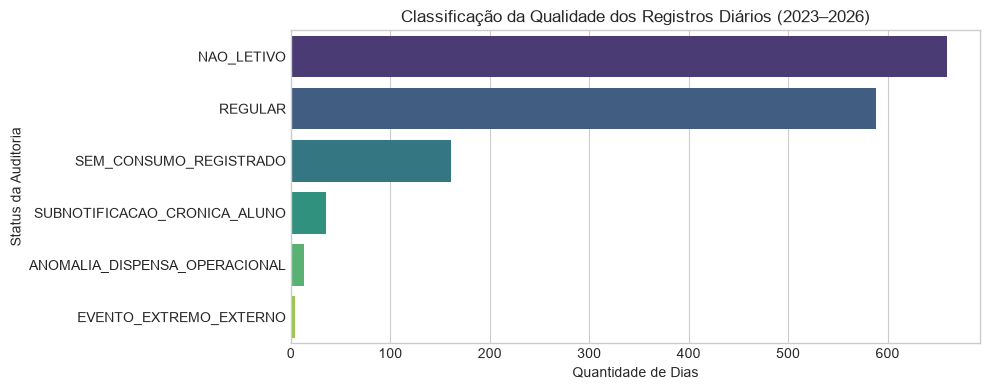

In [3]:
qualidade_counts = df_silver['status_qualidade_registro'].value_counts()
print("=== DISTRIBUIÇÃO DOS STATUS DE QUALIDADE ===")
print(qualidade_counts)

# Gráfico de barras da qualidade dos registros
plt.figure(figsize=(10, 4))
sns.barplot(x=qualidade_counts.values, y=qualidade_counts.index, palette="viridis")
plt.title("Classificação da Qualidade dos Registros Diários (2023–2026)")
plt.xlabel("Quantidade de Dias")
plt.ylabel("Status da Auditoria")
plt.tight_layout()
plt.show()

### 3. Evidências Empíricas das Anomalias Operacionais e Exógenas

Abaixo inspecionamos os casos críticos identificados:
1. **Dias com Dispensa/Interrupção Operacional:** Dias letivos regulares em que o consumo foi quase nulo (ex: 1, 5, 8 ou 14 refeições) apesar de haver turmas programadas.
2. **Eventos Climáticos Extremos:** Dias com enchentes severas em Itaquaquecetuba documentadas pelo pesquisador.

In [4]:
cols_view = ['data', 'dia_da_semana', 'status_qualidade_registro', 'reservas', 'consumo', 'diff_consumo_reserva', 'evento_tipo', 'observacao']

print("--- DIAS COM ANOMALIA DE DISPENSA/INTERRUPÇÃO (Consumo < 40 em dia letivo) ---")
dispensas = df_silver[df_silver['status_qualidade_registro'] == 'ANOMALIA_DISPENSA_OPERACIONAL'][cols_view]
print(dispensas.to_string())

print("\n--- EVENTOS EXTERNOS EXTREMOS (Enchentes / Greves) ---")
extremos = df_silver[df_silver['status_qualidade_registro'] == 'EVENTO_EXTREMO_EXTERNO'][cols_view]
print(extremos.to_string())

--- DIAS COM ANOMALIA DE DISPENSA/INTERRUPÇÃO (Consumo < 40 em dia letivo) ---
            data  dia_da_semana      status_qualidade_registro  reservas  consumo  diff_consumo_reserva               evento_tipo observacao
183   03/07/2023  segunda-feira  ANOMALIA_DISPENSA_OPERACIONAL      50.0     16.0                 -34.0      prazo_administrativo        NaN
184   04/07/2023    terça-feira  ANOMALIA_DISPENSA_OPERACIONAL      28.0      7.0                 -21.0              aula_regular        NaN
185   05/07/2023   quarta-feira  ANOMALIA_DISPENSA_OPERACIONAL      18.0      1.0                 -17.0              aula_regular        NaN
208   28/07/2023    sexta-feira  ANOMALIA_DISPENSA_OPERACIONAL      46.0     24.0                 -22.0              aula_regular        NaN
326   23/11/2023   quinta-feira  ANOMALIA_DISPENSA_OPERACIONAL      90.0     32.0                 -58.0  semana_consciencia_negra        NaN
331   28/11/2023    terça-feira  ANOMALIA_DISPENSA_OPERACIONAL      94.0   

### 4. Mudança Estrutural de Regime: Aluno Autodeclarado × Nutricionista Especialista

Comparação estatística entre os dois regimes de reservas/estimativas no IFSP Itaquaquecetuba:
* **2023–2025 (Alunos):** Tendência de subnotificação crônica (consumo real superava as reservas em até 34 refeições diárias).
* **2026 (Nutricionista):** Estimativa técnica mais correlacionada, porém com viés conservador (+15.4 refeições de margem de segurança).

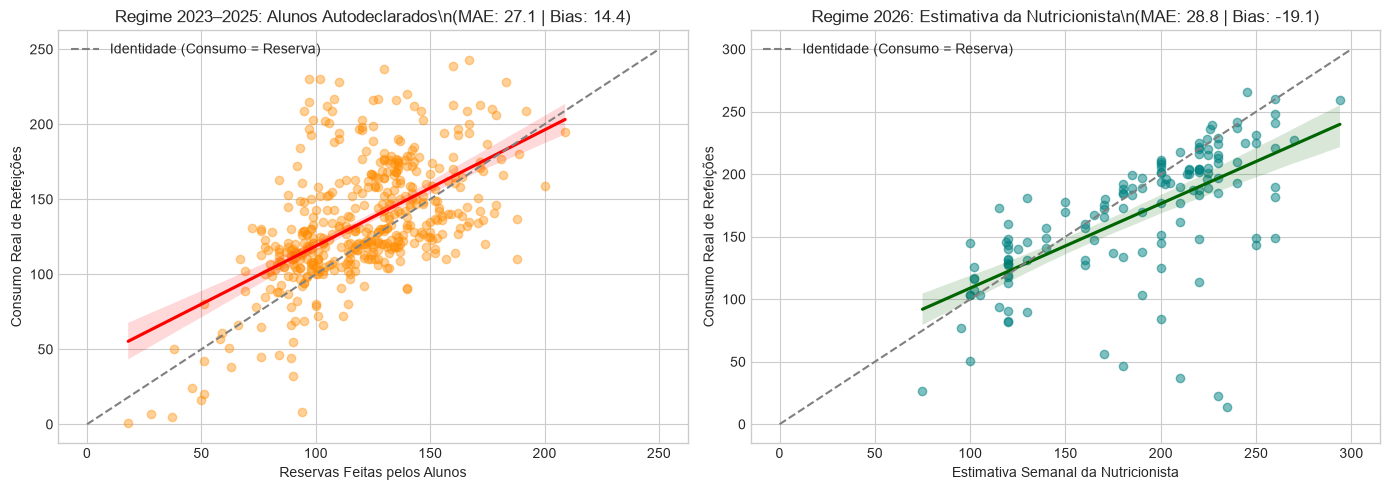

In [5]:
df_valid = df_silver[df_silver['consumo'].notna() & df_silver['reservas'].notna()].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dispersão 2023-2025
df_antigo = df_valid[df_valid['regime_reserva'] == 'aluno_manifestacao']
sns.regplot(ax=axes[0], data=df_antigo, x='reservas', y='consumo',
            scatter_kws={'alpha': 0.4, 'color': 'darkorange'}, line_kws={'color': 'red'})
axes[0].plot([0, 250], [0, 250], '--', color='gray', label='Identidade (Consumo = Reserva)')
axes[0].set_title(f"Regime 2023–2025: Alunos Autodeclarados\\n(MAE: {abs(df_antigo['diff_consumo_reserva']).mean():.1f} | Bias: {df_antigo['diff_consumo_reserva'].mean():.1f})")
axes[0].set_xlabel("Reservas Feitas pelos Alunos")
axes[0].set_ylabel("Consumo Real de Refeições")
axes[0].legend()

# Dispersão 2026
df_novo = df_valid[df_valid['regime_reserva'] == 'nutricionista_estimativa']
sns.regplot(ax=axes[1], data=df_novo, x='reservas', y='consumo',
            scatter_kws={'alpha': 0.5, 'color': 'teal'}, line_kws={'color': 'darkgreen'})
axes[1].plot([0, 300], [0, 300], '--', color='gray', label='Identidade (Consumo = Reserva)')
axes[1].set_title(f"Regime 2026: Estimativa da Nutricionista\\n(MAE: {abs(df_novo['diff_consumo_reserva']).mean():.1f} | Bias: {df_novo['diff_consumo_reserva'].mean():.1f})")
axes[1].set_xlabel("Estimativa Semanal da Nutricionista")
axes[1].set_ylabel("Consumo Real de Refeições")
axes[1].legend()

plt.tight_layout()
plt.show()

### 5. Diretrizes para a Camada Gold (Engenharia de Features)

A partir da camada Silver auditada:
1. **Filtro de Treinamento Imunizado:** Os registros com `status_qualidade_registro == 'ANOMALIA_DISPENSA_OPERACIONAL'` e `'EVENTO_EXTREMO_EXTERNO'` não devem ser usados diretamente como alvo de treino não tratado para prever dias normais.
2. **Sinalizadores Exógenos:** Criar variáveis que capturem a sensibilidade climática e o dia da semana.
3. **Calibrador de Viés da Nutricionista:** Em 2026, a previsão da nutricionista serve como excelente *baseline especialista*, que pode ser aprimorada pelos algoritmos de ML para reduzir a margem de sobras sem gerar rupturas.